1. Use default sample text
2. Enter custom text string


Select an option (1 or 2):  1



Using default sample text...

Input String: "huffman coding data compression module assignment text"

         DATA COMPRESSION MODULE             

 GENERATED HUFFMAN CODES:
Character    | Huffman Code   
------------------------------
'space'      | 011            
'a'          | 1111           
'c'          | 0010           
'd'          | 0101           
'e'          | 1010           
'f'          | 00111          
'g'          | 10010          
'h'          | 100110         
'i'          | 0100           
'l'          | 00110          
'm'          | 1011           
'n'          | 000            
'o'          | 1100           
'p'          | 110111         
'r'          | 110110         
's'          | 1000           
't'          | 1110           
'u'          | 11010          
'x'          | 100111         

 ENCODED OUTPUT STREAM:
1001101101000111001111011111100001100101100010101000001001001101011111111011110110010110010111101111101101010100010000100110000001110111100010111010

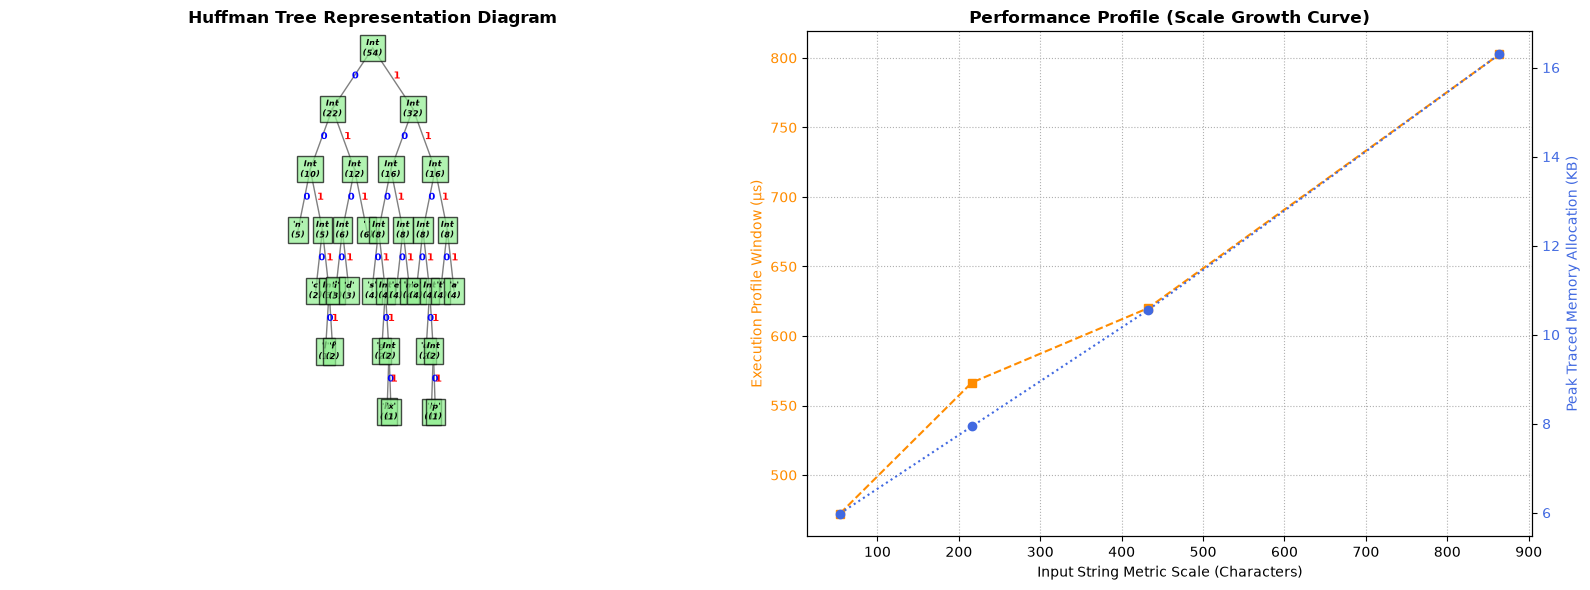

In [1]:
import heapq
import time
import tracemalloc
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

class Node:
    def __init__(self, char, freq):
        self.char = char
        self.freq = freq
        self.left = None
        self.right = None
        
    def __lt__(self, other):
        return self.freq < other.freq

def build_huffman_tree(text):
    frequencies = Counter(text)
    heap = [Node(char, freq) for char, freq in frequencies.items()]
    heapq.heapify(heap)
    
    if len(heap) == 0:
        return None
        
    if len(heap) == 1:
        root = Node(None, heap[0].freq)
        root.left = heap[0]
        return root
        
    while len(heap) > 1:
        node1 = heapq.heappop(heap)
        node2 = heapq.heappop(heap)
        merged = Node(None, node1.freq + node2.freq)
        merged.left = node1
        merged.right = node2
        heapq.heappush(heap, merged)
        
    return heap[0]

def generate_codes(root, current_code, codes):
    if root is None:
        return
    if root.char is not None:
        codes[root.char] = current_code
        return
    generate_codes(root.left, current_code + "0", codes)
    generate_codes(root.right, current_code + "1", codes)

def print_huffman_tree_topology(node, level=0, prefix="Root: "):
    if node is not None:
        print("    " * level + prefix + (f"[Char: '{node.char}' | Freq: {node.freq}]" if node.char else f"[Internal Node | Freq: {node.freq}]"))
        if node.left or node.right:
            print_huffman_tree_topology(node.left, level + 1, "L(--0)--> ")
            print_huffman_tree_topology(node.right, level + 1, "R(--1)--> ")

def huffman_compression(text):
    if not text:
        return {}, "", 0, 0, 0.0, None
        
    root = build_huffman_tree(text)
    codes = {}
    generate_codes(root, "", codes)
    
    encoded_text = "".join(codes[char] for char in text)
    original_size = len(text) * 8
    compressed_size = len(encoded_text)
    compression_ratio = original_size / compressed_size if compressed_size > 0 else 0.0
    
    return codes, encoded_text, original_size, compressed_size, compression_ratio, root

def plot_tree_pure_matplotlib(ax, node, x=0, y=0, dx=1.0, dy=1.0, current_depth=1):
    if node is None:
        return
    
    label = f"'{node.char}'\n({node.freq})" if node.char else f"Int\n({node.freq})"
    
    ax.text(x, y, label, style='italic', weight='bold',
            bbox={'facecolor': 'lightgreen', 'alpha': 0.7, 'pad': 2},
            horizontalalignment='center', verticalalignment='center', fontsize=6)
    
    # Dynamically compress horizontal spacing down the tree to limit leaf collisions
    next_dx = dx * 0.55 
    
    if node.left:
        next_x = x - dx
        next_y = y - dy
        ax.plot([x, next_x], [y, next_y], color='gray', linestyle='-', linewidth=1, zorder=1)
        ax.text((x + next_x)/2 - 0.06, (y + next_y)/2, '0', fontsize=7, color='blue', weight='bold')
        plot_tree_pure_matplotlib(ax, node.left, next_x, next_y, next_dx, dy, current_depth + 1)
        
    if node.right:
        next_x = x + dx
        next_y = y - dy
        ax.plot([x, next_x], [y, next_y], color='gray', linestyle='-', linewidth=1, zorder=1)
        ax.text((x + next_x)/2 + 0.06, (y + next_y)/2, '1', fontsize=7, color='red', weight='bold')
        plot_tree_pure_matplotlib(ax, node.right, next_x, next_y, next_dx, dy, current_depth + 1)

def display_visualizations(text, root, scaling_times, sizes, memory_allocs):
    fig, axs = plt.subplots(1, 2, figsize=(16, 6))
    
    axs[0].axis('off')
    if root is not None:
        # Increased baseline dx/dy width parameters to give lower branches breathing room
        plot_tree_pure_matplotlib(axs[0], root, x=0, y=0, dx=3.5, dy=1.8)
        
        def get_tree_depth(node):
            if node is None:
                return 0
            return 1 + max(get_tree_depth(node.left), get_tree_depth(node.right))
            
        depth = get_tree_depth(root)
        axs[0].set_xlim(-4.5 * depth, 4.5 * depth)
        axs[0].set_ylim(-2.0 * depth - 0.5, 0.5)
    axs[0].set_title("Huffman Tree Representation Diagram", fontsize=12, weight='bold')
    
    # Dual axis plot to elegantly combine Time and Memory scaling profiles
    color = 'darkorange'
    axs[1].plot(sizes, scaling_times, marker='s', linestyle='--', color=color, label='Time')
    axs[1].set_title("Performance Profile (Scale Growth Curve)", fontsize=12, weight='bold')
    axs[1].set_xlabel("Input String Metric Scale (Characters)")
    axs[1].set_ylabel("Execution Profile Window (μs)", color=color)
    axs[1].tick_params(axis='y', labelcolor=color)
    axs[1].grid(True, linestyle=':')
    
    ax2 = axs[1].twinx()
    color_mem = 'royalblue'
    ax2.plot(sizes, memory_allocs, marker='o', linestyle=':', color=color_mem, label='Peak Memory')
    ax2.set_ylabel("Peak Traced Memory Allocation (KB)", color=color_mem)
    ax2.tick_params(axis='y', labelcolor=color_mem)
    
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    print("1. Use default sample text")
    print("2. Enter custom text string")
    choice = input("Select an option (1 or 2): ").strip()
    
    if choice == "2":
        input_text = input("Enter the text to compress: ")
    else:
        print("\nUsing default sample text...")
        input_text = "huffman coding data compression module assignment text"
        
    print(f"\nInput String: \"{input_text}\"")
    
    # Measure baseline trackable peak allocation 
    tracemalloc.start()
    huffman_codes, encoded_out, orig_bits, comp_bits, comp_ratio, tree_root = huffman_compression(input_text)
    _, initial_peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    
    print("\n=============================================")
    print("         DATA COMPRESSION MODULE             ")
    print("=============================================")
    print("\n GENERATED HUFFMAN CODES:")
    print(f"{'Character':<12} | {'Huffman Code':<15}")
    print("-" * 30)
    for char in sorted(huffman_codes.keys()):
        display_char = f"'{char}'" if char != " " else "'space'"
        print(f"{display_char:<12} | {huffman_codes[char]:<15}")
        
    print("\n ENCODED OUTPUT STREAM:")
    print(encoded_out)
    
    print("\n COMPRESSION STATISTICS:")
    print(f"Original Size      : {orig_bits} bits ({len(input_text)} characters * 8 bits)")
    print(f"Compressed Size    : {comp_bits} bits")
    print(f"Compression Ratio  : {comp_ratio:.2f}x")
    print(f"Baseline Peak RAM  : {initial_peak_mem / 1024:.2f} KB")
    print("=============================================")
    
    print("\n HUFFMAN TREE TOPOLOGY REPRESENTATION :")
    print_huffman_tree_topology(tree_root)
    print("=============================================")
    
    # Scale profile run collecting both metrics
    sizes = [len(input_text), len(input_text) * 4, len(input_text) * 8, len(input_text) * 16]
    scaling_times = []
    memory_allocs = []
    
    for s in sizes:
        test_sample = input_text * (s // len(input_text))
        
        tracemalloc.start()
        t_start = time.perf_counter_ns()
        
        r_node = build_huffman_tree(test_sample)
        c_dict = {}
        if r_node:
            generate_codes(r_node, "", c_dict)
            _ = "".join(c_dict[ch] for ch in test_sample)
            
        scaling_times.append((time.perf_counter_ns() - t_start) / 1000)
        _, peak_mem = tracemalloc.get_traced_memory()
        memory_allocs.append(peak_mem / 1024)  # Store in KB
        tracemalloc.stop()
        
    display_visualizations(input_text, tree_root, scaling_times, sizes, memory_allocs)